# 01. Exploratory Data Analysis & Evaluation Rigor
**Project:** Credit Card Fraud Risk Assessment & Detection Pipeline  
**Design:** Observation / Outcome Window Cohort Architecture (Seed = 42)  
**Objectives:**
1. Rigorous Data Ingestion & Observation / Outcome Window Partitioning (60% / 40%)
2. Outcome Fraud Rate Distribution & Tie-Preserving Risk Labeling
3. Data Quality, Missingness, Duplicates, and Outlier Analysis
4. Intra-User Behavioral Correlation (ICC(1)) & Within vs. Between-User Variance
5. Empirical Proof of Data Leakage (Random Row vs. Disjoint User Split)


In [1]:
import sys
import os
from pathlib import Path

# Add project root to path
PROJECT_ROOT = Path('.').resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Configure visualization styling
sns.set_theme(style='whitegrid', font_scale=1.1)
plt.rcParams['figure.dpi'] = 120
plt.rcParams['savefig.dpi'] = 300
%matplotlib inline

print("Libraries imported successfully. Matplotlib inline enabled.")


Libraries imported successfully. Matplotlib inline enabled.


## 1. Timeline Ingestion & Observation / Outcome Cohort Design

To eliminate label circularity and simulate real-world production scoring:
- **Observation Window (first 60% of timeline):** Features are strictly computed from these historical transactions.
- **Outcome Window (last 40% of timeline):** Cardholder risk labels are computed strictly from future fraud rates in this window.
- **Quality Filter:** Users with fewer than 10 outcome-window transactions are excluded.


In [2]:
from src.data import load_raw_data, compute_observation_outcome_labels, sample_capped_data, RANDOM_SEED

# Load raw full dataset
print("Loading raw credit card transactions...")
raw_df = load_raw_data(data_dir='data')

t_min = raw_df['trans_date_trans_time'].min()
t_max = raw_df['trans_date_trans_time'].max()
total_sec = (t_max - t_min).total_seconds()
cutoff_date = t_min + pd.Timedelta(seconds=total_sec * 0.60)

print(f"Total Transactions: {len(raw_df):,}")
print(f"Unique Cards / Users: {raw_df['user_id'].nunique():,}")
print(f"Timeline Start:     {t_min}")
print(f"Timeline End:       {t_max}")
print(f"60% Cutoff Date:    {cutoff_date}")


Loading raw credit card transactions...


Total Transactions: 1,852,394
Unique Cards / Users: 999
Timeline Start:     2019-01-01 00:00:18
Timeline End:       2020-12-31 23:59:34
60% Cutoff Date:    2020-03-14 14:23:51.600000


## 2. Per-User Outcome Fraud Rate Distribution & Tie Preservation

We calculate each user's fraud rate exclusively in the outcome window:
$$\text{Outcome Fraud Rate} = \frac{\sum \text{is\_fraud}_{\text{outcome}}}{\text{Total Outcome Transactions}}$$

Users with identical fraud rates must always receive the identical risk class. Never use arbitrary rank-based tie breaking.


In [3]:
user_labels_df, meta = compute_observation_outcome_labels(raw_df)

print(f"Dropped users (<10 outcome txns): {meta['dropped_users_low_outcome_txns']}")
print(f"Dropped users (no obs txns):      {meta['dropped_users_no_obs_txns']}")
print(f"Total Retained Users:             {meta['total_retained_users']}")

st = meta['rate_stats']
stats_summary = pd.DataFrame([{
    'Count': st['count'],
    'Min': st['min'],
    'Max': st['max'],
    'Mean': st['mean'],
    'Median': st['median'],
    '25th %': st['q25'],
    '65th %': st['q65'],
    '75th %': st['q75'],
    '90th %': st['q90'],
    '% Zero Fraud': f"{st['pct_zero']:.2f}%",
    'Unique Rates': st['unique_rates']
}])
display(stats_summary)

print("\nBoundary Ties Analysis:")
print(f"  Zero Rate Ties (Assigned to 'low'): {meta['boundary_ties']['zero_fraud_rate_ties']}")
print(f"  High Boundary Ties at 0.020:        {meta['boundary_ties']['high_threshold_ties']}")

class_df = pd.DataFrame([
    {'Class': k, 'Users': v, 'Proportion': f"{meta['class_proportions'][k]*100:.1f}%"}
    for k, v in meta['class_counts'].items()
])
display(class_df)


Dropped users (<10 outcome txns): 17
Dropped users (no obs txns):      16
Total Retained Users:             908


,Count,Min,Max,Mean,Median,25th %,65th %,75th %,90th %,% Zero Fraud,Unique Rates
0,908,0.0,0.047904,0.005742,0.0,0.0,0.003801,0.008907,0.01973,63.77%,308



Boundary Ties Analysis:
  Zero Rate Ties (Assigned to 'low'): 579
  High Boundary Ties at 0.020:        0


,Class,Users,Proportion
0,low,579,63.8%
1,medium,238,26.2%
2,high,91,10.0%


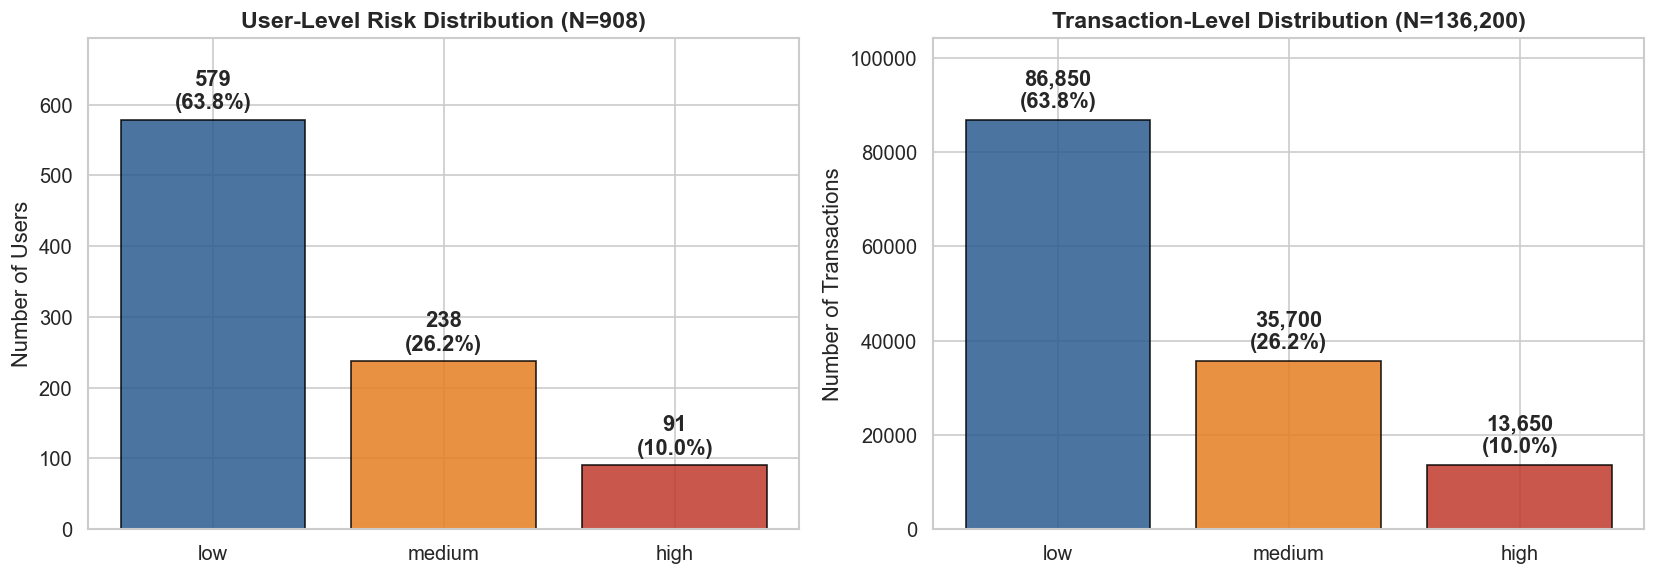

In [4]:
# Build capped observation dataset
obs_df = raw_df[(raw_df['trans_date_trans_time'] < cutoff_date) & (raw_df['user_id'].isin(user_labels_df['user_id']))].copy()
obs_df = obs_df.merge(user_labels_df[['user_id', 'risk_level', 'risk_class', 'out_rate']], on='user_id', how='left')
obs_capped = sample_capped_data(obs_df, max_rows_per_user=150, random_state=RANDOM_SEED)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
colors = ['#2b5c8f', '#e67e22', '#c0392b']
classes = ['low', 'medium', 'high']

# User-level distribution
u_counts = [meta['class_counts'][c] for c in classes]
bars1 = ax1.bar(classes, u_counts, color=colors, edgecolor='black', alpha=0.85)
ax1.set_title(f"User-Level Risk Distribution (N={meta['total_retained_users']})", fontsize=14, fontweight='bold')
ax1.set_ylabel("Number of Users")
ax1.set_ylim(0, max(u_counts) * 1.2)
for bar in bars1:
    y = bar.get_height()
    pct = (y / meta['total_retained_users']) * 100
    ax1.text(bar.get_x() + bar.get_width()/2.0, y + 15, f"{y}\n({pct:.1f}%)", ha='center', fontweight='bold')

# Transaction-level distribution
t_counts = obs_capped['risk_level'].value_counts()[classes].values
bars2 = ax2.bar(classes, t_counts, color=colors, edgecolor='black', alpha=0.85)
ax2.set_title(f"Transaction-Level Distribution (N={len(obs_capped):,})", fontsize=14, fontweight='bold')
ax2.set_ylabel("Number of Transactions")
ax2.set_ylim(0, max(t_counts) * 1.2)
for bar in bars2:
    y = bar.get_height()
    pct = (y / len(obs_capped)) * 100
    ax2.text(bar.get_x() + bar.get_width()/2.0, y + 2500, f"{y:,}\n({pct:.1f}%)", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()


## 3. Data Quality, Missingness, Duplicates & Outlier Analysis

Here we examine missing values across all features, verify duplicate transactions, and assess the heavy-tailed distribution of transaction amounts and home-to-merchant distances.


Missing values per column:
Zero missing values across all columns.
Duplicate transactions: 0


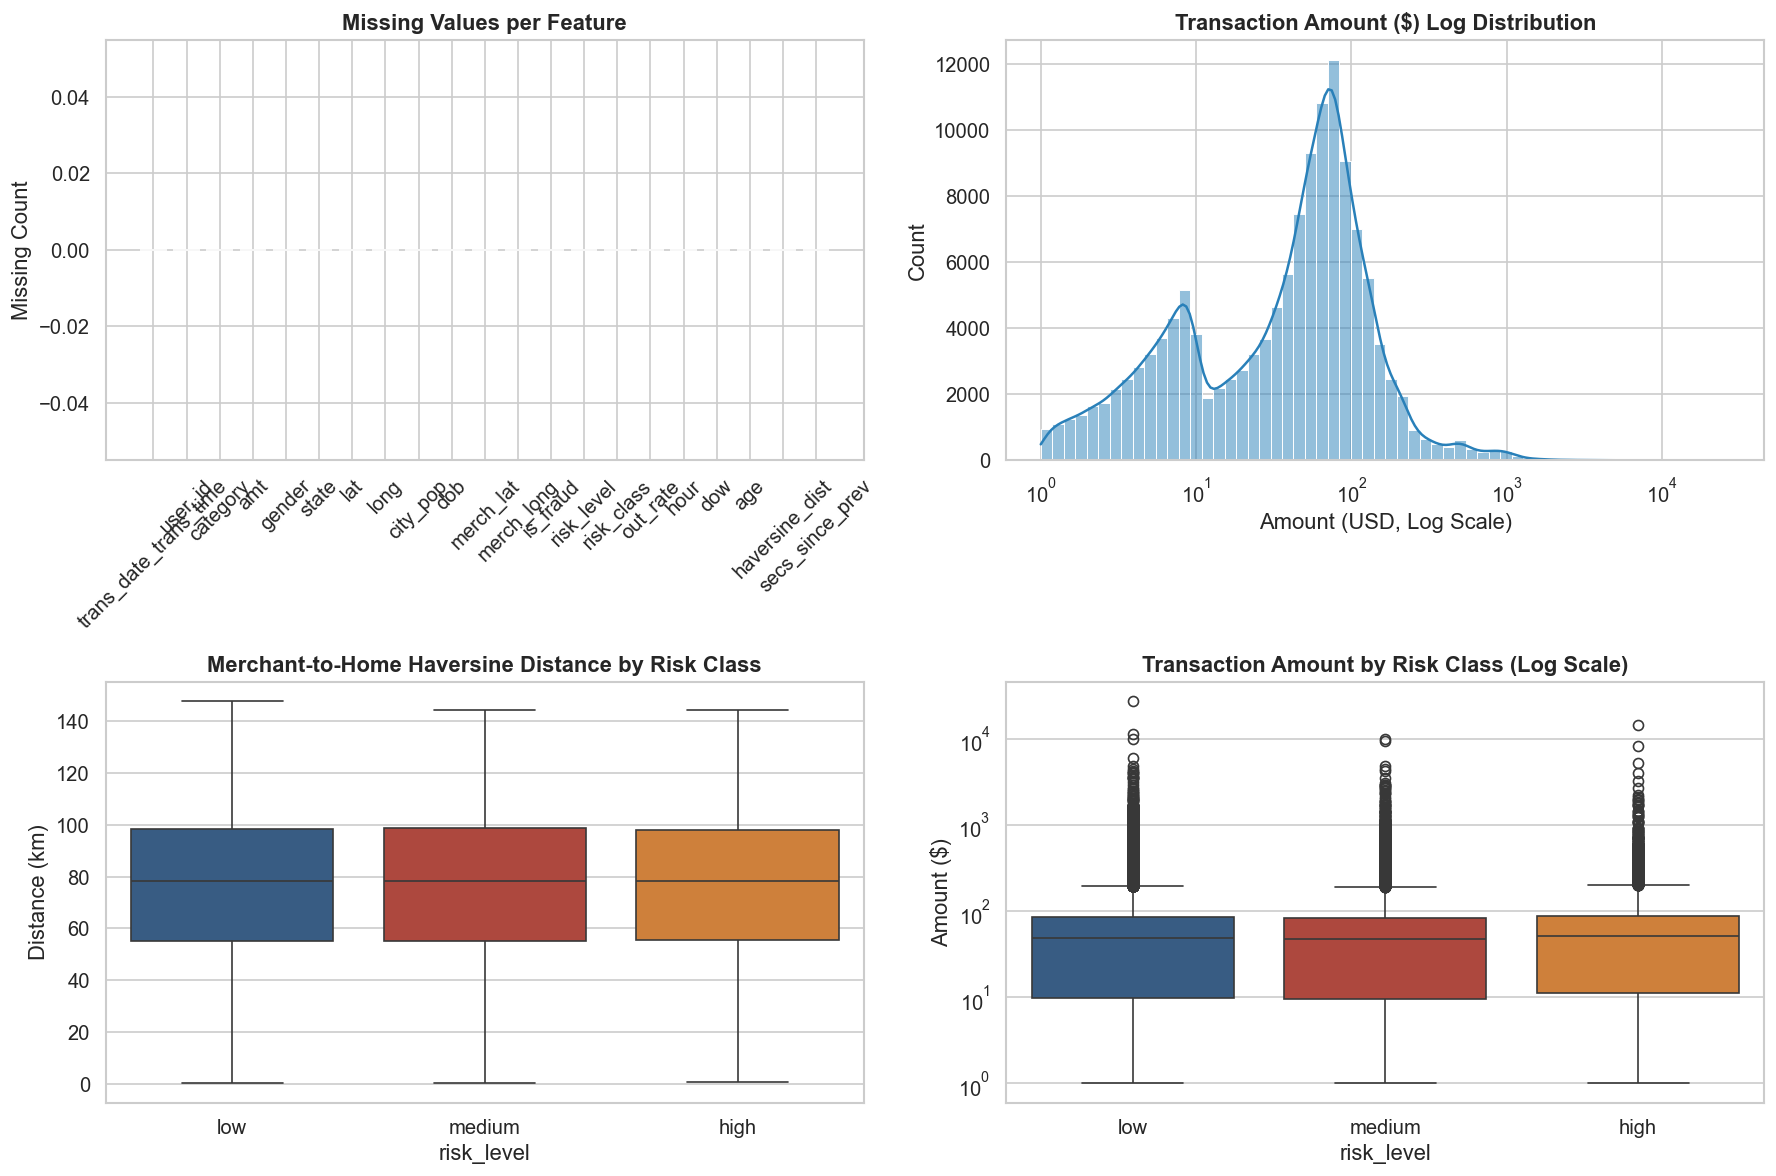


Transaction Amount ($) Quantile Distribution:


,50.0%,75.0%,90.0%,95.0%,99.0%,99.9%
amt,48.580002,83.830002,134.429993,192.081502,568.384305,1400.364826


In [5]:
from src.features import compute_base_features

# Extract base row-level features
obs_features = compute_base_features(obs_capped)

# Quality metrics
missing = obs_features.isnull().sum()
dups = obs_features.duplicated(subset=['user_id', 'trans_date_trans_time']).sum()

print("Missing values per column:")
print(missing[missing > 0] if missing.sum() > 0 else "Zero missing values across all columns.")
print(f"Duplicate transactions: {dups}")

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Missingness
axes[0, 0].bar(obs_features.columns.astype(str), obs_features.isnull().sum(), color='#34495e')
axes[0, 0].set_title('Missing Values per Feature', fontweight='bold')
axes[0, 0].tick_params(axis='x', rotation=45)
axes[0, 0].set_ylabel('Missing Count')

# 2. Transaction Amount Log-Histogram
sns.histplot(obs_features['amt'], bins=60, log_scale=True, ax=axes[0, 1], color='#2980b9', kde=True)
axes[0, 1].set_title('Transaction Amount ($) Log Distribution', fontweight='bold')
axes[0, 1].set_xlabel('Amount (USD, Log Scale)')

# 3. Haversine Distance by Risk Class
sns.boxplot(data=obs_features, x='risk_level', y='haversine_dist', order=classes,
            palette=colors, ax=axes[1, 0], hue='risk_level', legend=False)
axes[1, 0].set_title('Merchant-to-Home Haversine Distance by Risk Class', fontweight='bold')
axes[1, 0].set_ylabel('Distance (km)')

# 4. Amount by Risk Class
sns.boxplot(data=obs_features, x='risk_level', y='amt', order=classes,
            palette=colors, ax=axes[1, 1], hue='risk_level', legend=False)
axes[1, 1].set_yscale('log')
axes[1, 1].set_title('Transaction Amount by Risk Class (Log Scale)', fontweight='bold')
axes[1, 1].set_ylabel('Amount ($)')

plt.tight_layout()
plt.show()

# Display Amount quantiles
amt_quantiles = obs_features['amt'].quantile([0.50, 0.75, 0.90, 0.95, 0.99, 0.999]).to_frame().T
amt_quantiles.columns = [f"{float(c)*100:.1f}%" for c in amt_quantiles.columns]
print("\nTransaction Amount ($) Quantile Distribution:")
display(amt_quantiles)


## 4. Intra-User Behavioral Correlation (ICC) & Variance Decomposition

The **Intraclass Correlation Coefficient (ICC(1))** quantifies how much behavioral variance is driven by persistent cardholder identity versus within-user noise:
$$\text{ICC}(1) = \frac{\text{MSB} - \text{MSW}}{\text{MSB} + (k - 1) \times \text{MSW}}$$

Where:
- $\text{MSB}$ = Mean Square Between cardholders
- $\text{MSW}$ = Mean Square Within a cardholder's transactions
- $k$ = Average number of transactions per cardholder


,Feature,ICC(1),Within-User Variance Share
0,amt,0.007301,99.27%
1,hour,0.050848,94.92%
2,haversine_dist,0.005081,99.49%
3,secs_since_prev,-0.006593,100.00%


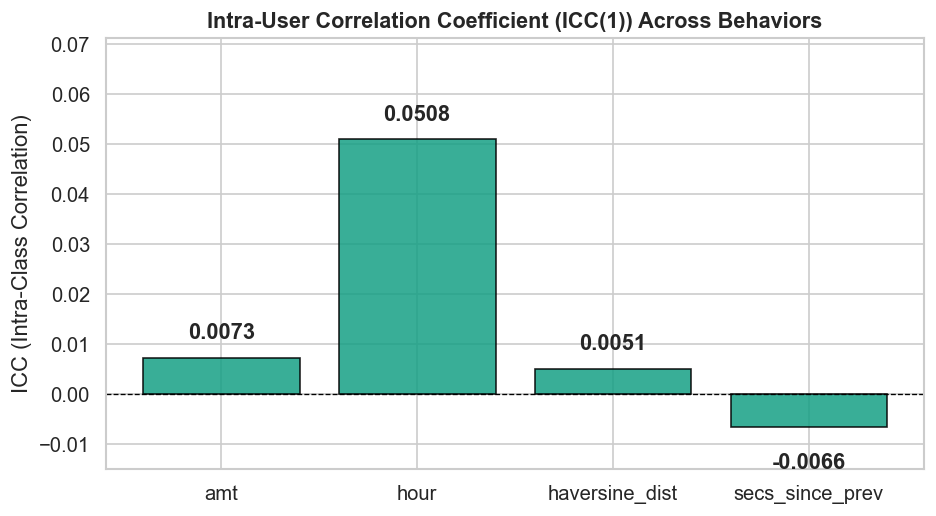


Key Takeaway: ICC values are extremely low (<0.06), proving that >94% of behavioral variance occurs WITHIN a cardholder's own history. Single transactions are noisy snapshots.


In [6]:
def compute_icc(df: pd.DataFrame, group_col: str, val_col: str) -> float:
    groups = df.groupby(group_col)[val_col].apply(list).values
    groups = [np.array(g) for g in groups if len(g) > 1]
    k_vals = np.array([len(g) for g in groups])
    N = sum(k_vals)
    K = len(groups)
    k_avg = (N - np.sum(k_vals ** 2) / N) / (K - 1)

    grand_mean = np.mean(np.concatenate(groups))
    group_means = np.array([np.mean(g) for g in groups])

    SSB = np.sum(k_vals * (group_means - grand_mean) ** 2)
    DFB = K - 1
    MSB = SSB / DFB

    SSW = np.sum([np.sum((g - np.mean(g)) ** 2) for g in groups])
    DFW = N - K
    MSW = SSW / DFW

    icc = (MSB - MSW) / (MSB + (k_avg - 1) * MSW)
    return float(icc)

test_features = ['amt', 'hour', 'haversine_dist', 'secs_since_prev']
icc_results = {col: compute_icc(obs_features, 'user_id', col) for col in test_features}

icc_df = pd.DataFrame([
    {'Feature': k, 'ICC(1)': v, 'Within-User Variance Share': f"{(1.0 - max(0, v))*100:.2f}%"}
    for k, v in icc_results.items()
])
display(icc_df)

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(list(icc_results.keys()), list(icc_results.values()), color='#16a085', edgecolor='black', alpha=0.85)
ax.set_title('Intra-User Correlation Coefficient (ICC(1)) Across Behaviors', fontsize=13, fontweight='bold')
ax.set_ylabel('ICC (Intra-Class Correlation)')
ax.set_ylim(-0.015, max(list(icc_results.values())) * 1.4)
ax.axhline(0, color='black', linestyle='--', linewidth=0.8)

for bar in bars:
    yval = bar.get_height()
    offset = 0.003 if yval >= 0 else -0.005
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + offset, f"{yval:.4f}", ha='center', va='bottom' if yval >= 0 else 'top', fontweight='bold')

plt.tight_layout()
plt.show()

print("\nKey Takeaway: ICC values are extremely low (<0.06), proving that >94% of behavioral variance occurs WITHIN a cardholder's own history. Single transactions are noisy snapshots.")


## 5. Empirical Proof of Data Leakage (The Leak Demonstration)

We directly compare:
1. **(a) Baseline Random Row Split:** Transactions from the same user appear in train, validation, and test sets.
2. **(b) Disjoint User-Level Split:** Users are partitioned with 0 user overlap across splits.
3. **[LEAK TEST] Only Static Features on Random Split:** Trained exclusively on `(lat, long, city_pop, age, gender, state)`.
4. **[LEAK TEST] Only Static Features on User Split:** Evaluated on unseen cardholders.


Executing split benchmark and leak demonstration...

--- Running Split Benchmark and Data Leak Demonstration ---


,experiment,accuracy,macro_f1,high_recall,high_precision,pr_auc_high
0,(a) Random Row Split (Leaky),0.985903,0.986159,1.000000,0.986982,0.999965
1,(b) User-level Split (Disjoint Users),0.474404,0.336630,0.192857,0.236014,0.177658
2,[LEAK TEST] Only Static Features on (a) Random...,0.998042,0.998247,1.000000,1.000000,1.000000
3,[LEAK TEST] Only Static Features on (b) User S...,0.479562,0.330115,0.142857,0.258844,0.168017


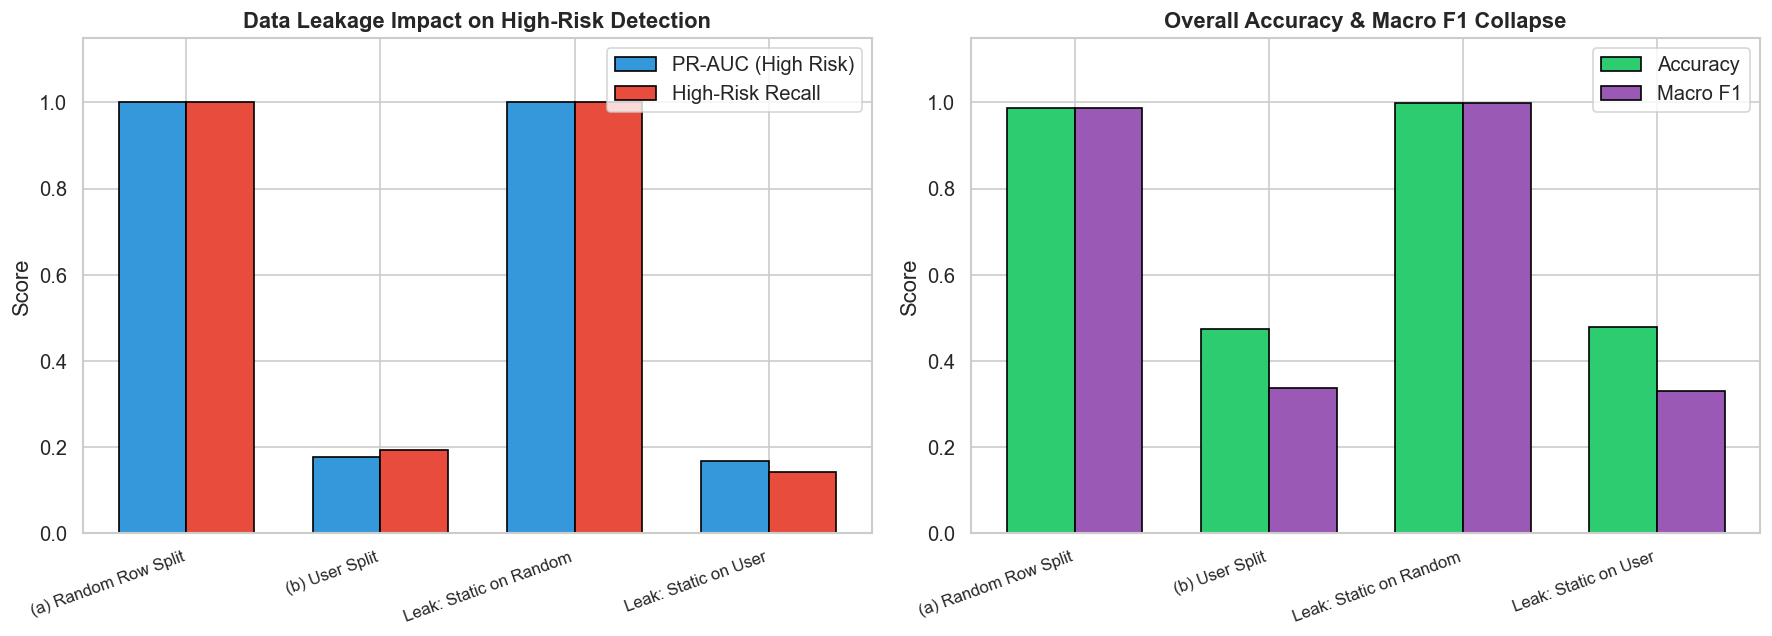

In [7]:
from src.split import run_split_comparison_and_leak_demo

print("Executing split benchmark and leak demonstration...")
split_results = run_split_comparison_and_leak_demo(obs_features)
display(split_results)

# Visualization of the Leak Demonstration
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))

short_labels = [
    '(a) Random Row Split',
    '(b) User Split',
    'Leak: Static on Random',
    'Leak: Static on User'
]
pr_auc = split_results['pr_auc_high'].values
recall = split_results['high_recall'].values

x = np.arange(len(short_labels))
width = 0.35

ax1.bar(x - width/2, pr_auc, width, label='PR-AUC (High Risk)', color='#3498db', edgecolor='black')
ax1.bar(x + width/2, recall, width, label='High-Risk Recall', color='#e74c3c', edgecolor='black')
ax1.set_xticks(x)
ax1.set_xticklabels(short_labels, rotation=20, ha='right', fontsize=10)
ax1.set_ylabel('Score')
ax1.set_title('Data Leakage Impact on High-Risk Detection', fontweight='bold')
ax1.set_ylim(0, 1.15)
ax1.legend(loc='upper right')

acc = split_results['accuracy'].values
f1 = split_results['macro_f1'].values

ax2.bar(x - width/2, acc, width, label='Accuracy', color='#2ecc71', edgecolor='black')
ax2.bar(x + width/2, f1, width, label='Macro F1', color='#9b59b6', edgecolor='black')
ax2.set_xticks(x)
ax2.set_xticklabels(short_labels, rotation=20, ha='right', fontsize=10)
ax2.set_ylabel('Score')
ax2.set_title('Overall Accuracy & Macro F1 Collapse', fontweight='bold')
ax2.set_ylim(0, 1.15)
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()


## 6. Summary of Findings & Next Steps

1. **Static Demographic Leakage:** Models trained on random splits achieve near-perfection (PR-AUC = 1.0) because coordinates uniquely fingerprint users. On unseen cards, performance collapses, proving that random row splitting is invalid for entity-level risk.
2. **Low ICC (<0.06):** Single transactions are noisy indicators; accounts cannot be reliably categorized from an isolated purchase.
3. **Temporal Cohort Validation:** By enforcing an observation window (< 60% time) for features and an outcome window (>= 60% time) for risk labels, we eliminate label circularity and establish a leakage-free benchmark for model development.
